# Predicción de resultados de peleas de UFC

## Avance del proyecto

Comparamos los datos previos de los dos peleadores para estimar qué esquina gana: roja o azul. En este avance revisamos el CSV, probamos tres modelos y evaluamos sus resultados con peleas más recientes que las usadas para entrenar.

## 2. Importar librerías

Usaremos pandas y NumPy para los datos, Matplotlib y Seaborn para las gráficas y scikit-learn junto con XGBoost para los modelos.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

# El notebook puede ejecutarse desde la raíz del proyecto o desde notebooks/.
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / 'data' / 'raw' / 'data.csv').exists():
    PROJECT_DIR = PROJECT_DIR.parent
RAW_PATH = PROJECT_DIR / 'data' / 'raw' / 'data.csv'
PROCESSED_DIR = PROJECT_DIR / 'data' / 'processed'
FIGURES_DIR = PROJECT_DIR / 'reports' / 'figures'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

if not RAW_PATH.exists():
    raise FileNotFoundError(f'No se encontró el CSV original: {RAW_PATH}')
print(f'Proyecto: {PROJECT_DIR.resolve()}')
print(f'CSV: {RAW_PATH.resolve()}')

Proyecto: C:\Users\kenne\OneDrive\Desktop\UFC\ufc-predictor
CSV: C:\Users\kenne\OneDrive\Desktop\UFC\ufc-predictor\data\raw\data.csv


## 3. Carga de datos y primer vistazo

El archivo original tiene muchas columnas de estadísticas de pelea. Para este avance mostramos solo los campos relevantes para el resultado y los predictores previos al combate.

In [2]:
raw_df = pd.read_csv(RAW_PATH)
print(f'Dataset: {raw_df.shape[0]:,} peleas y {raw_df.shape[1]:,} columnas en total')
columnas_clave = [
    'Date', 'winner', 'R_Name', 'B_Name', 'R_Age', 'B_Age',
    'R_Height', 'B_Height', 'R_Weight', 'B_Weight',
    'RPrev', 'BPrev', 'RStreak', 'BStreak'
]
columnas_clave = [columna for columna in columnas_clave if columna in raw_df.columns]
display(raw_df[columnas_clave].head())
display(raw_df[columnas_clave].describe(include='all').T)

Dataset: 1,477 peleas y 895 columnas en total


,Date,winner,R_Name,B_Name,R_Age,B_Age,R_Height,B_Height,R_Weight,B_Weight,RPrev,BPrev,RStreak,BStreak
0,01/02/2017,red,Antonio Carlos Junior,Marvin Vettori,27.0,23.0,187,182.0,84,84,6,1,1,1
1,06/30/2014,blue,Colton Smith,Carlos Diego Ferreira,29.0,32.0,182,175.0,70,70,0,0,0,0
2,07/27/2015,red,Joe Lauzon,Takanori Gomi,32.0,38.0,177,172.0,70,70,2,2,0,0
3,10/03/2016,blue,Louis Smolka,Brandon Moreno,25.0,23.0,175,170.0,56,56,6,0,4,0
4,08/22/2016,red,Raquel Pennington,Elizabeth Phillips,28.0,30.0,170,167.0,61,61,5,3,2,1


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date,1477,224,07/11/2016,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
winner,1477,4,red,867,NaN,NaN,NaN,NaN,NaN,NaN,NaN
R_Name,1477,633,Donald Cerrone,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
B_Name,1477,719,Tim Means,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
R_Age,1476.0,NaN,NaN,NaN,31.380081,4.098927,21.0,28.0,31.0,34.0,46.0
B_Age,1474.0,NaN,NaN,NaN,30.954545,4.020311,20.0,28.0,31.0,34.0,46.0
R_Height,1477.0,NaN,NaN,NaN,177.436696,8.667657,154.0,172.0,177.0,185.0,213.0
B_Height,1476.0,NaN,NaN,NaN,177.45122,8.561541,152.0,172.0,177.0,182.0,213.0
R_Weight,1477.0,NaN,NaN,NaN,73.935003,15.069751,52.0,65.0,70.0,84.0,120.0
B_Weight,1477.0,NaN,NaN,NaN,73.804333,14.980531,52.0,65.0,70.0,84.0,120.0


## 4. Limpieza de datos

Conservamos intacto el CSV de `data/raw/` y limpiamos una copia. Convertimos `Date` a fecha y las columnas numéricas relevantes a números. Quitamos filas duplicadas exactas. Los valores objetivo `draw` y `no contest` se excluyen después, porque no son victorias de rojo o azul.

In [3]:
df = raw_df.copy()
duplicados_antes = df.duplicated().sum()
df = df.drop_duplicates().copy()
print(f'Duplicados exactos eliminados: {duplicados_antes}')

if 'Date' not in df.columns or 'winner' not in df.columns:
    raise KeyError('El CSV debe incluir las columnas reales Date y winner.')

# El formato observado en el CSV es mes/día/año; el segundo parseo cubre otras variantes.
df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y', errors='coerce')
fechas_invalidas = df['Date'].isna().sum()
if fechas_invalidas:
    fechas_restantes = pd.to_datetime(raw_df.loc[df.index, 'Date'], errors='coerce')
    df['Date'] = df['Date'].fillna(fechas_restantes)
print(f'Fechas no interpretables: {df["Date"].isna().sum()}')

columnas_numericas = [
    'B_Age', 'R_Age', 'B_Height', 'R_Height', 'B_Weight', 'R_Weight',
    'BPrev', 'RPrev', 'BStreak', 'RStreak'
]
for columna in columnas_numericas:
    if columna in df.columns:
        df[columna] = pd.to_numeric(df[columna], errors='coerce')

print(f'Filas y columnas tras quitar duplicados: {df.shape}')
display(df.isna().sum().sort_values(ascending=False).head(15).to_frame('valores_nulos'))
print('\nTipos de datos de los campos relevantes:')
display(df[[c for c in ['Date', 'winner'] + columnas_numericas if c in df.columns]].dtypes.to_frame('tipo'))
print('\nResultados registrados:')
display(df['winner'].astype('string').str.lower().value_counts(dropna=False).to_frame('peleas'))

Duplicados exactos eliminados: 0
Fechas no interpretables: 10
Filas y columnas tras quitar duplicados: (1477, 895)


,valores_nulos
B__Round4_Strikes_Leg Total Strikes_Landed,1471
B__Round4_Strikes_Leg Total Strikes_Attempts,1471
B__Round5_Strikes_Leg Total Strikes_Landed,1471
B__Round5_Strikes_Leg Total Strikes_Attempts,1471
R__Round4_Strikes_Leg Total Strikes_Attempts,1450
R__Round5_Strikes_Leg Total Strikes_Attempts,1450
R__Round5_Strikes_Leg Total Strikes_Landed,1450
R__Round4_Strikes_Leg Total Strikes_Landed,1450
B__Round5_Strikes_Legs Total Strikes_Attempts,1420
B__Round5_Strikes_Legs Total Strikes_Landed,1420



Tipos de datos de los campos relevantes:


,tipo
Date,datetime64[us]
winner,str
B_Age,float64
R_Age,float64
B_Height,float64
R_Height,int64
B_Weight,int64
R_Weight,int64
BPrev,int64
RPrev,int64



Resultados registrados:


,peleas
winner,
red,867
blue,584
no contest,17
draw,9


## 5. Análisis exploratorio de datos

Exploramos los resultados, características físicas y correlaciones. Antes de graficar categorías de peso, métodos de victoria o alcance, comprobamos que esas columnas existan en el CSV: en este archivo no están incluidas, así que el notebook lo indicará claramente. Las estadísticas por ronda describen la pelea ya ocurrida y no se usarán como predictores.

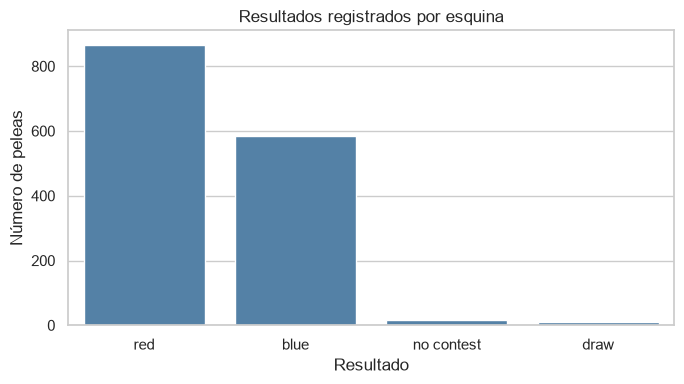

No se puede graficar categoría de peso: no hay una columna correspondiente en el CSV.
No se puede graficar método de victoria: no hay una columna correspondiente en el CSV.


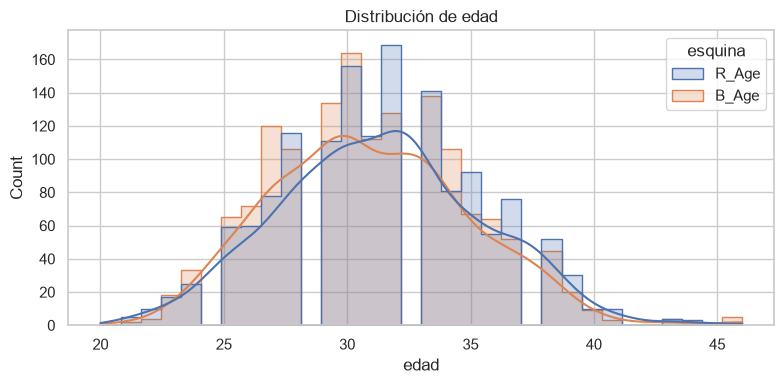

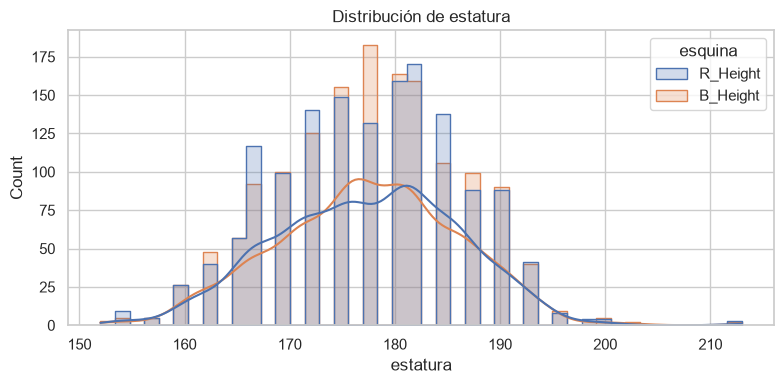

No se puede mostrar la distribución de alcance: el CSV no contiene esos datos.


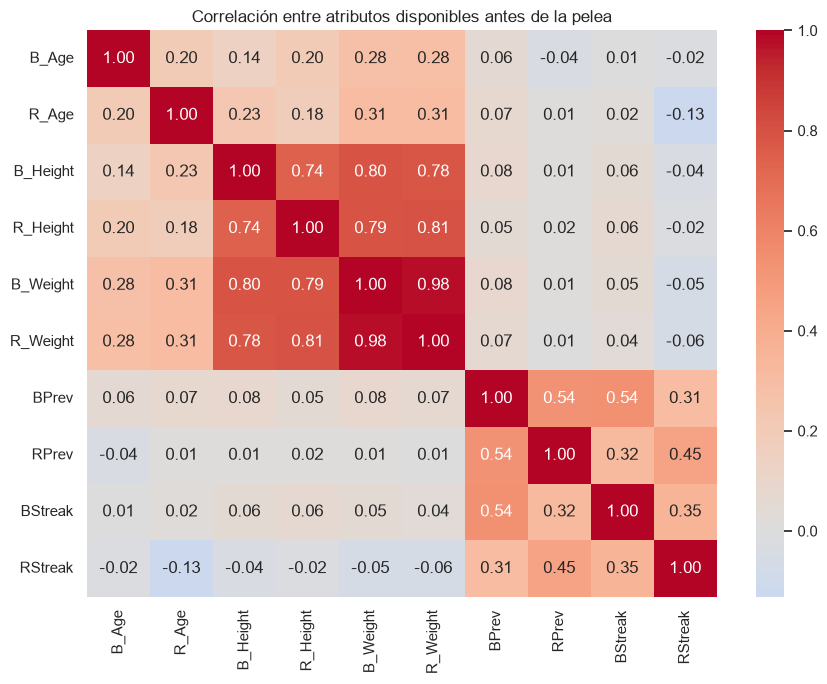

In [4]:
# Victorias por esquina: draws y no contest se muestran aparte solo si existen.
conteo_resultados = df['winner'].astype('string').str.lower().value_counts()
plt.figure(figsize=(7, 4))
sns.barplot(x=conteo_resultados.index, y=conteo_resultados.values, color='steelblue')
plt.title('Resultados registrados por esquina')
plt.xlabel('Resultado'); plt.ylabel('Número de peleas')
plt.tight_layout(); plt.savefig(FIGURES_DIR / '01_resultados_por_esquina.png', dpi=150); plt.show()

# El CSV no trae estas columnas: evitamos atribuir categorías o métodos inexistentes.
for titulo, posibles in [
    ('Categoría de peso', ['WeightClass', 'weight_class', 'weightclass', 'Division']),
    ('Método de victoria', ['Finish', 'Method', 'method', 'finish_method'])
]:
    encontrada = next((col for col in posibles if col in df.columns), None)
    if encontrada:
        plt.figure(figsize=(10, 5))
        df[encontrada].value_counts().head(15).plot(kind='bar', color='teal')
        plt.title(f'Peleas por {titulo.lower()}')
        plt.ylabel('Número de peleas'); plt.tight_layout()
        plt.savefig(FIGURES_DIR / f'02_{titulo.lower().replace(" ", "_")}.png', dpi=150)
        plt.show()
    else:
        print(f'No se puede graficar {titulo.lower()}: no hay una columna correspondiente en el CSV.')

# Histogramas de edad y estatura disponibles; alcance se comprueba por separado.
for nombre, columnas in [
    ('edad', ['R_Age', 'B_Age']),
    ('estatura', ['R_Height', 'B_Height']),
    ('alcance', ['R_Reach', 'B_Reach'])
]:
    disponibles = [c for c in columnas if c in df.columns]
    if disponibles:
        valores = df[disponibles].melt(var_name='esquina', value_name=nombre)
        valores[nombre] = pd.to_numeric(valores[nombre], errors='coerce')
        plt.figure(figsize=(8, 4))
        sns.histplot(data=valores, x=nombre, hue='esquina', kde=True, element='step')
        plt.title(f'Distribución de {nombre}'); plt.tight_layout()
        plt.savefig(FIGURES_DIR / f'03_distribucion_{nombre}.png', dpi=150)
        plt.show()
    else:
        print(f'No se puede mostrar la distribución de {nombre}: el CSV no contiene esos datos.')

# El mapa de calor se limita a atributos pre-pelea reales (sin métricas de la pelea).
columnas_correlacion = [c for c in columnas_numericas if c in df.columns]
correlaciones = df[columnas_correlacion].corr(numeric_only=True)
plt.figure(figsize=(9, 7))
sns.heatmap(correlaciones, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlación entre atributos disponibles antes de la pelea')
plt.tight_layout(); plt.savefig(FIGURES_DIR / '04_correlaciones_pre_pelea.png', dpi=150); plt.show()

## 6. Ingeniería de variables sin fuga de información

Solo usamos una lista blanca de columnas verificadas que describen características disponibles antes de la pelea: edad, estatura, peso, peleas previas y racha. Creamos diferencias **azul menos rojo** y conservamos sus valores por esquina. No se usan nombres, identificadores, ganador ni estadísticas de la pelea actual. Si falta una columna opcional, se omite sin error.

In [5]:
pares = {
    'edad': ('B_Age', 'R_Age'),
    'estatura': ('B_Height', 'R_Height'),
    'peso': ('B_Weight', 'R_Weight'),
    'peleas_previas': ('BPrev', 'RPrev'),
    'racha_previa': ('BStreak', 'RStreak')
}

features = pd.DataFrame(index=df.index)
for nombre, (azul, rojo) in pares.items():
    if azul in df.columns and rojo in df.columns:
        features[f'azul_{nombre}'] = pd.to_numeric(df[azul], errors='coerce')
        features[f'rojo_{nombre}'] = pd.to_numeric(df[rojo], errors='coerce')
        features[f'diferencia_{nombre}_azul_menos_rojo'] = features[f'azul_{nombre}'] - features[f'rojo_{nombre}']
    else:
        print(f'Se omiten {azul}/{rojo}: no están las dos columnas en el CSV.')

if features.shape[1] == 0:
    raise ValueError('No se encontraron pares de predictores pre-pelea reconocidos.')
print(f'Variables pre-pelea creadas ({features.shape[1]}): {features.columns.tolist()}')
display(features.head())

Variables pre-pelea creadas (15): ['azul_edad', 'rojo_edad', 'diferencia_edad_azul_menos_rojo', 'azul_estatura', 'rojo_estatura', 'diferencia_estatura_azul_menos_rojo', 'azul_peso', 'rojo_peso', 'diferencia_peso_azul_menos_rojo', 'azul_peleas_previas', 'rojo_peleas_previas', 'diferencia_peleas_previas_azul_menos_rojo', 'azul_racha_previa', 'rojo_racha_previa', 'diferencia_racha_previa_azul_menos_rojo']


,azul_edad,rojo_edad,diferencia_edad_azul_menos_rojo,azul_estatura,rojo_estatura,diferencia_estatura_azul_menos_rojo,azul_peso,rojo_peso,diferencia_peso_azul_menos_rojo,azul_peleas_previas,rojo_peleas_previas,diferencia_peleas_previas_azul_menos_rojo,azul_racha_previa,rojo_racha_previa,diferencia_racha_previa_azul_menos_rojo
0,23.0,27.0,-4.0,182.0,187,-5.0,84,84,0,1,6,-5,1,1,0
1,32.0,29.0,3.0,175.0,182,-7.0,70,70,0,0,0,0,0,0,0
2,38.0,32.0,6.0,172.0,177,-5.0,70,70,0,2,2,0,0,0,0
3,23.0,25.0,-2.0,170.0,175,-5.0,56,56,0,0,6,-6,0,4,-4
4,30.0,28.0,2.0,167.0,170,-3.0,61,61,0,3,5,-2,1,2,-1


## 7. Variable objetivo binaria

Codificamos `winner`: rojo es `1` y azul es `0`. Como el objetivo solicitado es una clasificación binaria, los empates, resultados sin decisión y etiquetas faltantes no se incorporan al entrenamiento.

In [6]:
resultado = df['winner'].astype('string').str.strip().str.lower()
mascara_binaria = resultado.isin(['red', 'blue']) & df['Date'].notna()
X = features.loc[mascara_binaria].copy()
y = resultado.loc[mascara_binaria].map({'red': 1, 'blue': 0}).astype('int64')
fechas_modelo = df.loc[mascara_binaria, 'Date'].copy()
print(f'Peleas binarias utilizables: {len(y):,}')
print('Codificación: red=1, blue=0')
display(y.value_counts().rename(index={1: 'rojo (1)', 0: 'azul (0)'}).to_frame('peleas'))

Peleas binarias utilizables: 1,441
Codificación: red=1, blue=0


,peleas
winner,
rojo (1),861
azul (0),580


## 8. Separación de entrenamiento y prueba por fecha

Ordenamos las peleas de la más antigua a la más reciente y reservamos el 20% final para prueba. No mezclamos aleatoriamente las fechas: así simulamos entrenar con el pasado y predecir peleas futuras.

In [7]:
orden = fechas_modelo.sort_values(kind='mergesort').index
X_ordenado = X.loc[orden]
y_ordenado = y.loc[orden]
fechas_ordenadas = fechas_modelo.loc[orden]
if len(X_ordenado) < 5:
    raise ValueError('Se necesitan al menos cinco peleas válidas para separar train y test.')
corte = int(len(X_ordenado) * 0.8)
corte = min(max(corte, 1), len(X_ordenado) - 1)
X_train, X_test = X_ordenado.iloc[:corte], X_ordenado.iloc[corte:]
y_train, y_test = y_ordenado.iloc[:corte], y_ordenado.iloc[corte:]
fecha_corte = fechas_ordenadas.iloc[corte]
print(f'Train: {len(X_train):,} peleas, {fechas_ordenadas.iloc[0].date()} a {fechas_ordenadas.iloc[corte - 1].date()}')
print(f'Test:  {len(X_test):,} peleas, {fechas_ordenadas.iloc[corte].date()} a {fechas_ordenadas.iloc[-1].date()}')
print(f'Fecha de corte cronológico: {fecha_corte.date()}')

# Guardamos solo variables autorizadas, fecha y objetivo; nunca las 895 columnas crudas.
datos_procesados = X_ordenado.copy()
datos_procesados.insert(0, 'Date', fechas_ordenadas)
datos_procesados['winner_red'] = y_ordenado
datos_procesados.to_csv(PROCESSED_DIR / 'ufc_features.csv', index=False)
print(f'Datos de modelado guardados en: {PROCESSED_DIR / "ufc_features.csv"}')

Train: 1,152 peleas, 2014-01-05 a 2016-09-17
Test:  289 peleas, 2016-09-19 a 2017-04-16
Fecha de corte cronológico: 2016-09-19
Datos de modelado guardados en: C:\Users\kenne\OneDrive\Desktop\UFC\ufc-predictor\data\processed\ufc_features.csv


## 9. Modelos

Comparamos una regresión logística como línea base con Random Forest y XGBoost. La imputación reemplaza faltantes por la mediana calculada **solo con entrenamiento**; la logística también estandariza las variables. El split sigue siendo temporal para los tres modelos.

In [8]:
modelos = {
    'Regresión logística': make_pipeline(
        SimpleImputer(strategy='median'),
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
    ),
    'Random Forest': make_pipeline(
        SimpleImputer(strategy='median'),
        RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1)
    ),
    'XGBoost': make_pipeline(
        SimpleImputer(strategy='median'),
        XGBClassifier(n_estimators=250, max_depth=3, learning_rate=0.05,
                      subsample=0.9, colsample_bytree=0.9, eval_metric='logloss',
                      random_state=RANDOM_STATE, n_jobs=-1)
    )
}

resultados = {}
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    predicciones = modelo.predict(X_test)
    accuracy = accuracy_score(y_test, predicciones)
    resultados[nombre] = {'modelo': modelo, 'predicciones': predicciones, 'accuracy': accuracy}
    print(f'{nombre}: accuracy = {accuracy:.3f}')

Regresión logística: accuracy = 0.554


Random Forest: accuracy = 0.571


XGBoost: accuracy = 0.529


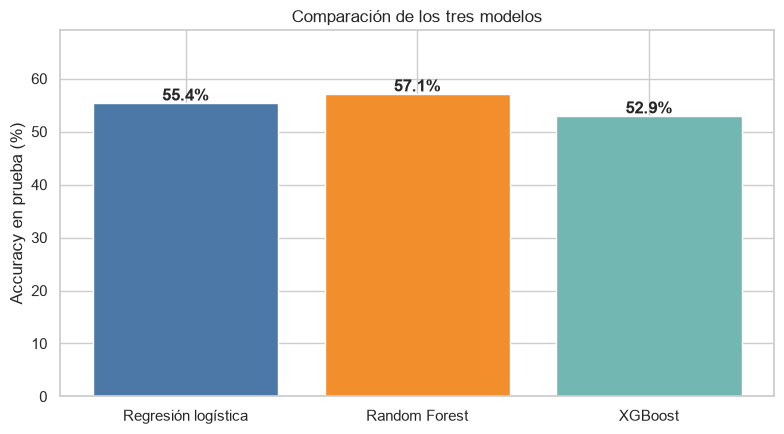

Mejor resultado en esta prueba: Random Forest


In [9]:
# Comparar visualmente la exactitud de los tres modelos
nombres_modelos = list(resultados.keys())
accuracies = [resultados[nombre]['accuracy'] * 100 for nombre in nombres_modelos]
colores = ['#4C78A8', '#E45756', '#72B7B2']
colores[nombres_modelos.index('Random Forest')] = '#F28E2B'

fig, ax = plt.subplots(figsize=(8, 4.5))
barras = ax.bar(nombres_modelos, accuracies, color=colores)
ax.set_ylim(0, max(accuracies) + 12)
ax.set_ylabel('Accuracy en prueba (%)')
ax.set_title('Comparación de los tres modelos')
for barra, valor in zip(barras, accuracies):
    ax.text(barra.get_x() + barra.get_width() / 2, valor + 0.5,
            f'{valor:.1f}%', ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '07_comparacion_modelos.png', dpi=150)
plt.show()

mejor_modelo = max(resultados, key=lambda nombre: resultados[nombre]['accuracy'])
print(f'Mejor resultado en esta prueba: {mejor_modelo}')

## 10. Evaluación e importancia de variables

La accuracy resume la proporción de aciertos; la matriz de confusión y el classification report muestran los errores por clase. La importancia se calcula según cada algoritmo: magnitud del coeficiente para logística y `feature_importances_` para los modelos de árboles. Son asociaciones predictivas, no causalidad.


### Regresión logística — accuracy: 0.554
              precision    recall  f1-score   support

    Azul (0)       0.48      0.29      0.36       126
    Rojo (1)       0.58      0.76      0.66       163

    accuracy                           0.55       289
   macro avg       0.53      0.52      0.51       289
weighted avg       0.54      0.55      0.53       289



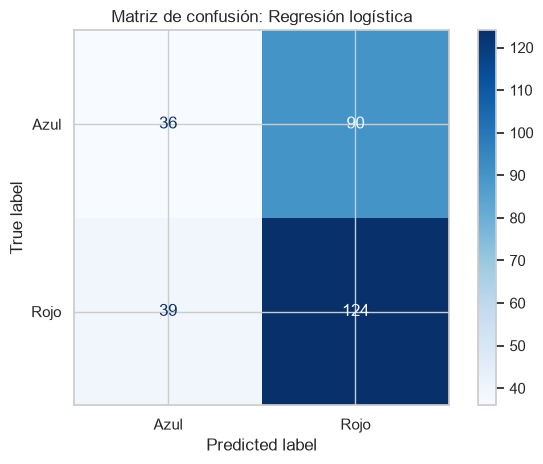

,importancia
azul_edad,0.466433
rojo_edad,0.380813
diferencia_edad_azul_menos_rojo,0.195512
azul_peleas_previas,0.146947
diferencia_peleas_previas_azul_menos_rojo,0.145861
rojo_estatura,0.094361
rojo_peso,0.083908
azul_estatura,0.073479
azul_peso,0.073328
diferencia_peso_azul_menos_rojo,0.047838


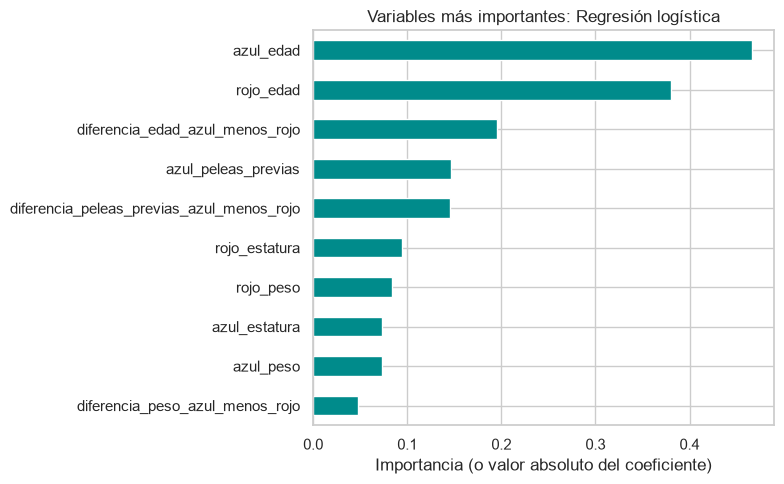


### Random Forest — accuracy: 0.571
              precision    recall  f1-score   support

    Azul (0)       0.51      0.36      0.42       126
    Rojo (1)       0.60      0.74      0.66       163

    accuracy                           0.57       289
   macro avg       0.55      0.55      0.54       289
weighted avg       0.56      0.57      0.56       289



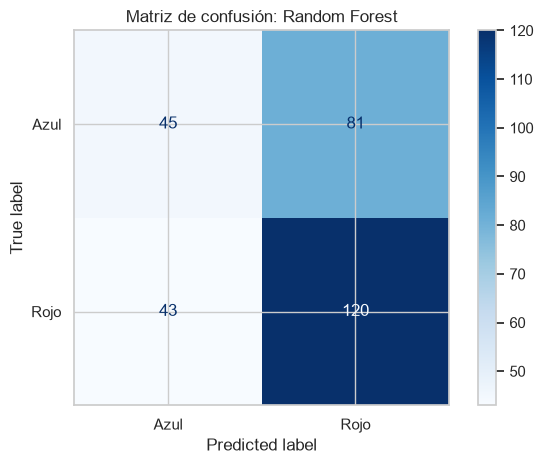

,importancia
diferencia_edad_azul_menos_rojo,0.124655
azul_edad,0.110129
rojo_edad,0.097809
diferencia_estatura_azul_menos_rojo,0.090632
rojo_estatura,0.080708
azul_estatura,0.079401
diferencia_peleas_previas_azul_menos_rojo,0.058477
azul_peleas_previas,0.056887
rojo_peso,0.054539
azul_peso,0.054134


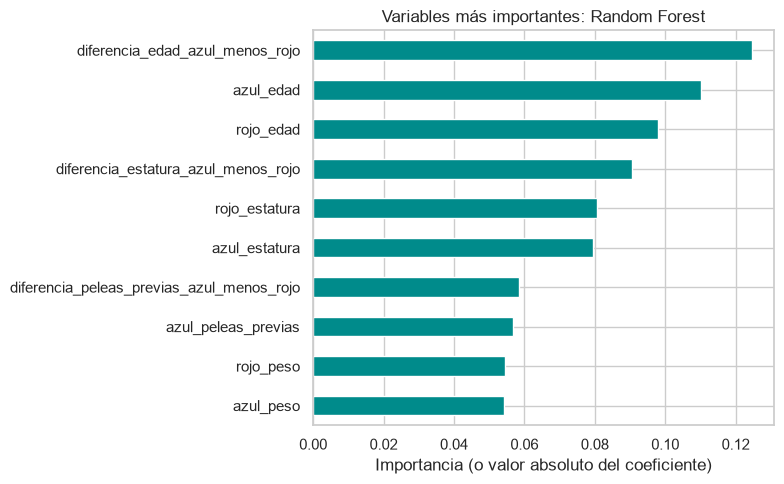


### XGBoost — accuracy: 0.529
              precision    recall  f1-score   support

    Azul (0)       0.45      0.37      0.41       126
    Rojo (1)       0.57      0.65      0.61       163

    accuracy                           0.53       289
   macro avg       0.51      0.51      0.51       289
weighted avg       0.52      0.53      0.52       289



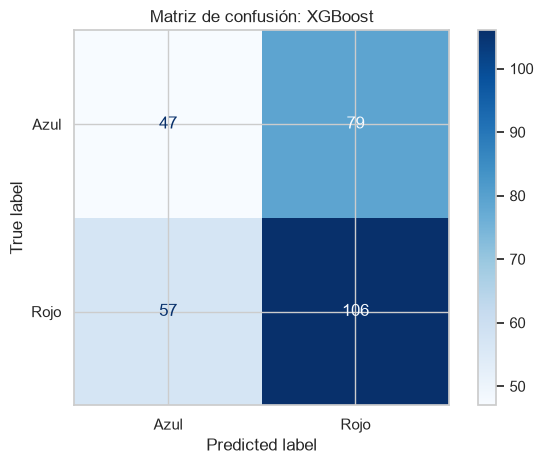

,importancia
azul_racha_previa,0.083397
diferencia_edad_azul_menos_rojo,0.078854
diferencia_peleas_previas_azul_menos_rojo,0.075785
azul_peleas_previas,0.073062
azul_edad,0.070818
rojo_edad,0.068631
diferencia_racha_previa_azul_menos_rojo,0.068309
rojo_estatura,0.065867
diferencia_peso_azul_menos_rojo,0.061308
azul_estatura,0.061229


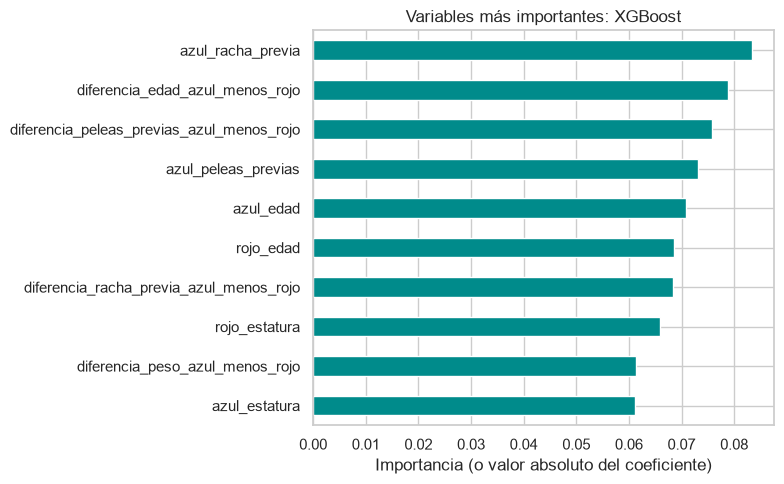

In [10]:
for nombre, resultado_modelo in resultados.items():
    predicciones = resultado_modelo['predicciones']
    print(f'\n### {nombre} — accuracy: {resultado_modelo["accuracy"]:.3f}')
    print(classification_report(y_test, predicciones, labels=[0, 1],
                                target_names=['Azul (0)', 'Rojo (1)'], zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicciones, labels=[0, 1], display_labels=['Azul', 'Rojo'], cmap='Blues'
    )
    plt.title(f'Matriz de confusión: {nombre}')
    plt.tight_layout()
    nombre_archivo = nombre.lower().replace(' ', '_').replace('ó', 'o')
    plt.savefig(FIGURES_DIR / f'05_matriz_{nombre_archivo}.png', dpi=150)
    plt.show()

    pipeline = resultado_modelo['modelo']
    estimador = pipeline.steps[-1][1]
    if nombre == 'Regresión logística':
        importancia = np.abs(estimador.coef_[0])
    else:
        importancia = estimador.feature_importances_
    tabla_importancia = pd.Series(importancia, index=X_train.columns).sort_values(ascending=False).head(10)
    display(tabla_importancia.rename('importancia').to_frame())
    ax = tabla_importancia.sort_values().plot(kind='barh', figsize=(8, 5), color='darkcyan')
    ax.set_title(f'Variables más importantes: {nombre}')
    ax.set_xlabel('Importancia (o valor absoluto del coeficiente)')
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f'06_importancia_{nombre_archivo}.png', dpi=150)
    plt.show()

## 11. Resultados y siguientes pasos

Random Forest obtuvo 57.1% de accuracy; regresión logística, 55.4%; y XGBoost, 52.9%. La referencia que siempre elige rojo obtiene 56.4%, así que la mejora de Random Forest es pequeña. En la prueba, el modelo reconoce mejor las victorias rojas que las azules.

Se entrenó con peleas hasta el 17 de septiembre de 2016 y se probó con las posteriores, desde el 19 de septiembre de 2016. Estos resultados son modestos y no demuestran que el modelo pueda predecir de forma confiable peleas actuales.

Como siguiente paso, hace falta conseguir datos históricos más completos y comprobar el modelo con otros periodos.

Las variables procesadas se guardan en `data/processed/ufc_features.csv` y las gráficas en `reports/figures/`.

## 12. Ejemplos visuales: probabilidades de combates históricos

Estos tres combates pertenecen al conjunto de prueba. Cada gráfico circular reparte el 100% de probabilidad estimada entre los peleadores: rojo representa la esquina roja y azul la esquina azul. Son ejemplos históricos, no pronósticos de peleas futuras.

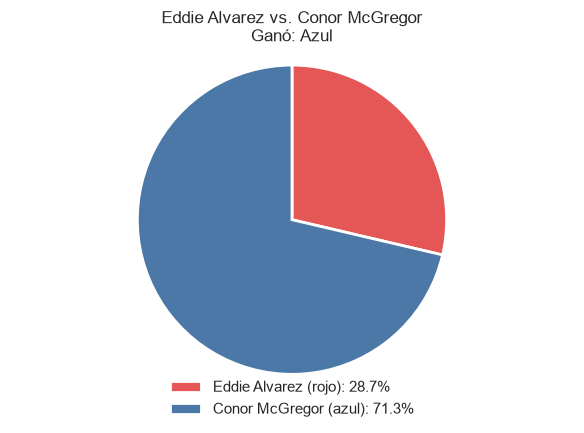

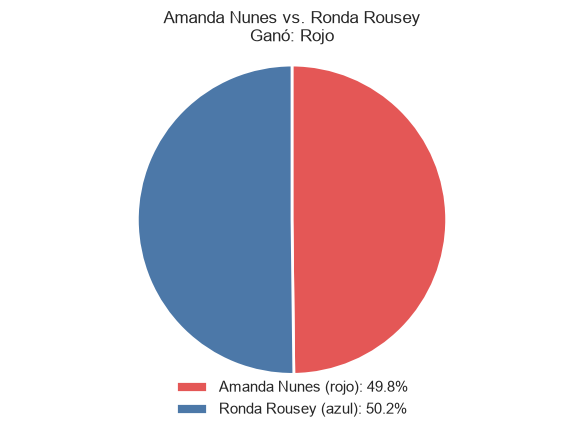

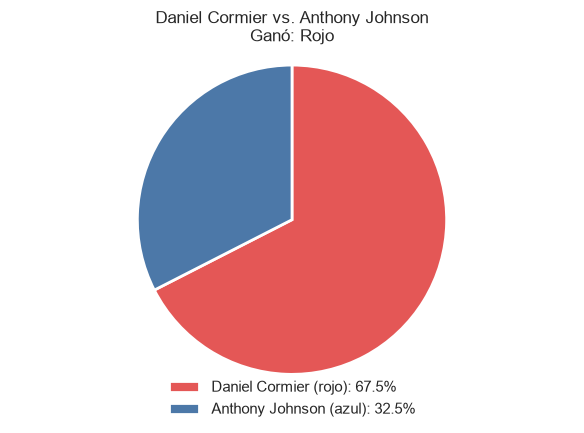

In [11]:
# Usamos las probabilidades del Random Forest evaluado en las peleas recientes.
rf_model = resultados['Random Forest']['modelo']
probabilidades_test = rf_model.predict_proba(X_test)
ejemplos_graficas = [
    ('Eddie Alvarez', 'Conor McGregor'),
    ('Amanda Nunes', 'Ronda Rousey'),
    ('Daniel Cormier', 'Anthony Johnson'),
]

for peleador_rojo, peleador_azul in ejemplos_graficas:
    coincidencias = [
        posicion for posicion, indice in enumerate(X_test.index)
        if df.loc[indice, 'R_Name'] == peleador_rojo
        and df.loc[indice, 'B_Name'] == peleador_azul
    ]
    if not coincidencias:
        print(f'No se encontró en prueba: {peleador_rojo} vs. {peleador_azul}')
        continue

    posicion = coincidencias[0]
    prob_rojo = probabilidades_test[posicion, 1]
    prob_azul = probabilidades_test[posicion, 0]
    resultado_real = {'RED': 'Rojo', 'BLUE': 'Azul'}.get(
        str(df.loc[X_test.index[posicion], 'winner']).upper(), 'Sin resultado'
    )

    fig, ax = plt.subplots(figsize=(6, 4.5))
    porciones, _ = ax.pie(
        [prob_rojo, prob_azul],
        colors=['#E45756', '#4C78A8'],
        startangle=90,
        counterclock=False,
        wedgeprops={'edgecolor': 'white', 'linewidth': 2}
    )
    ax.legend(
        porciones,
        [f'{peleador_rojo} (rojo): {prob_rojo:.1%}',
         f'{peleador_azul} (azul): {prob_azul:.1%}'],
        loc='lower center', bbox_to_anchor=(0.5, -0.12), frameon=False
    )
    ax.set_title(
        f'{peleador_rojo} vs. {peleador_azul}\nGanó: {resultado_real}'
    )
    ax.axis('equal')
    fig.tight_layout()
    nombre_archivo = (
        f'10_probabilidades_{peleador_rojo}_{peleador_azul}'
        .lower().replace(' ', '_').replace('.', '') + '.png'
    )
    fig.savefig(FIGURES_DIR / nombre_archivo, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)